   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst texture  worst perimeter  worst area  \
0             

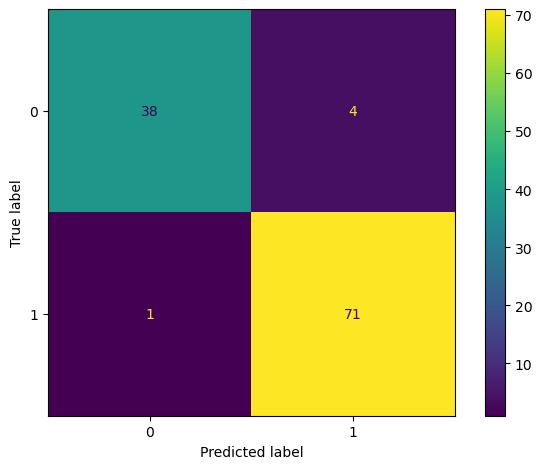

Saved model to adaboost.joblib


In [2]:
#adaboost
!pip install scikit-learn pandas matplotlib joblib
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
 ConfusionMatrixDisplay, precision_score, recall_score, f1_score)
from sklearn.base import clone

data = load_breast_cancer(as_frame=True)
df = data.frame.drop_duplicates().dropna()
X = df.drop(columns="target")
y = df["target"]

print(df.head())
print("Missing values:", int(df.isna().sum().sum()))
print("Class counts:\\n", y.value_counts())

X_train, X_test, y_train, y_test = train_test_split(
 X, y, test_size=0.20, random_state=42, stratify=y
)
from sklearn.ensemble import AdaBoostClassifier
model = AdaBoostClassifier(random_state=42)
steps = [("model", model)]
pipe = Pipeline(steps)

search = GridSearchCV(pipe, {"model__n_estimators": [30, 60], "model__learning_rate": [0.5, 1.0]}, cv=3, scoring="f1_weighted", n_jobs=-1)
search.fit(X_train, y_train)
best_model = search.best_estimator_
print("Best parameters:", search.best_params_)

pred = best_model.predict(X_test)
print(classification_report(y_test, pred, zero_division=0))
print("Accuracy:", accuracy_score(y_test, pred))
print("Precision:", precision_score(y_test, pred, average="weighted", zero_division=0))
print("Recall:", recall_score(y_test, pred, average="weighted", zero_division=0))
print("F1:", f1_score(y_test, pred, average="weighted", zero_division=0))
print("Confusion matrix:\\n", confusion_matrix(y_test, pred))
ConfusionMatrixDisplay.from_predictions(y_test, pred)
plt.tight_layout()
plt.show()

joblib.dump(best_model, "adaboost.joblib")
print("Saved model to adaboost.joblib")

   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst texture  worst perimeter  worst area  \
0             

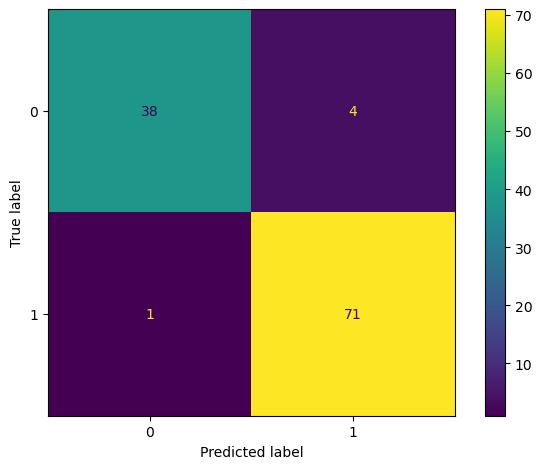

Saved model to gradient_boosting.joblib


In [4]:
#gradient boosting
!pip install scikit-learn pandas matplotlib joblib
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
 ConfusionMatrixDisplay, precision_score, recall_score, f1_score)
from sklearn.base import clone

data = load_breast_cancer(as_frame=True)
df = data.frame.drop_duplicates().dropna()
X = df.drop(columns="target")
y = df["target"]

print(df.head())
print("Missing values:", int(df.isna().sum().sum()))
print("Class counts:\\n", y.value_counts())

X_train, X_test, y_train, y_test = train_test_split(
 X, y, test_size=0.20, random_state=42, stratify=y
)
from sklearn.ensemble import GradientBoostingClassifier
model = GradientBoostingClassifier(random_state=42)
steps = [("model", model)]
pipe = Pipeline(steps)

search = GridSearchCV(pipe, {"model__n_estimators": [50, 100], "model__learning_rate": [0.05, 0.1]}, cv=3, scoring="f1_weighted", n_jobs=-1)
search.fit(X_train, y_train)
best_model = search.best_estimator_
print("Best parameters:", search.best_params_)

pred = best_model.predict(X_test)
print(classification_report(y_test, pred, zero_division=0))
print("Accuracy:", accuracy_score(y_test, pred))
print("Precision:", precision_score(y_test, pred, average="weighted", zero_division=0))
print("Recall:", recall_score(y_test, pred, average="weighted", zero_division=0))
print("F1:", f1_score(y_test, pred, average="weighted", zero_division=0))
print("Confusion matrix:\\n", confusion_matrix(y_test, pred))
ConfusionMatrixDisplay.from_predictions(y_test, pred)
plt.tight_layout()
plt.show()

joblib.dump(best_model, "gradient_boosting.joblib")
print("Saved model to gradient_boosting.joblib")

   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst texture  worst perimeter  worst area  \
0             

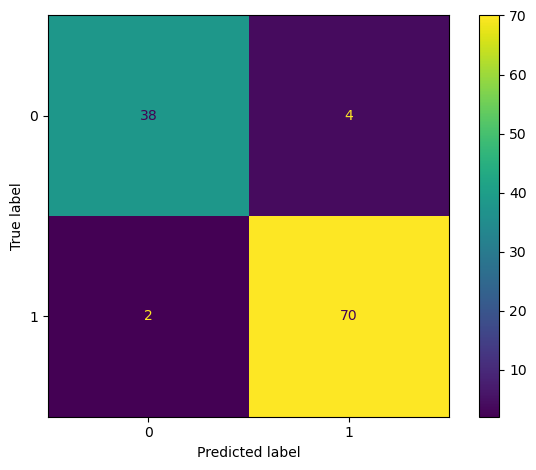

Saved model to xgboost.joblib


In [6]:
#XGBoost
!pip install scikit-learn pandas matplotlib joblib
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
 ConfusionMatrixDisplay, precision_score, recall_score, f1_score)
from sklearn.base import clone

data = load_breast_cancer(as_frame=True)
df = data.frame.drop_duplicates().dropna()
X = df.drop(columns="target")
y = df["target"]

print(df.head())
print("Missing values:", int(df.isna().sum().sum()))
print("Class counts:\\n", y.value_counts())

X_train, X_test, y_train, y_test = train_test_split(
 X, y, test_size=0.20, random_state=42, stratify=y
)
from xgboost import XGBClassifier 
model = XGBClassifier(eval_metric="logloss", random_state=42, n_jobs=-1)
steps = [("model", model)]
pipe = Pipeline(steps)

search = GridSearchCV(pipe, {"model__n_estimators": [50, 100], "model__max_depth": [3, 5]}, cv=3, scoring="f1_weighted", n_jobs=-1)
search.fit(X_train, y_train)
best_model = search.best_estimator_
print("Best parameters:", search.best_params_)

pred = best_model.predict(X_test)
print(classification_report(y_test, pred, zero_division=0))
print("Accuracy:", accuracy_score(y_test, pred))
print("Precision:", precision_score(y_test, pred, average="weighted", zero_division=0))
print("Recall:", recall_score(y_test, pred, average="weighted", zero_division=0))
print("F1:", f1_score(y_test, pred, average="weighted", zero_division=0))
print("Confusion matrix:\\n", confusion_matrix(y_test, pred))
ConfusionMatrixDisplay.from_predictions(y_test, pred)
plt.tight_layout()
plt.show()

joblib.dump(best_model, "xgboost.joblib")
print("Saved model to xgboost.joblib")

   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 1.4/1.4 MB 8.8 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2

  File "C:\Users\praja\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\praja\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\praja\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\praja\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^


Best parameters: {'model__n_estimators': 100, 'model__num_leaves': 15}
              precision    recall  f1-score   support

           0       0.97      0.93      0.95        42
           1       0.96      0.99      0.97        72

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114

Accuracy: 0.9649122807017544
Precision: 0.9651849217638692
Recall: 0.9649122807017544
F1: 0.9647247085304307
Confusion matrix:\n [[39  3]
 [ 1 71]]


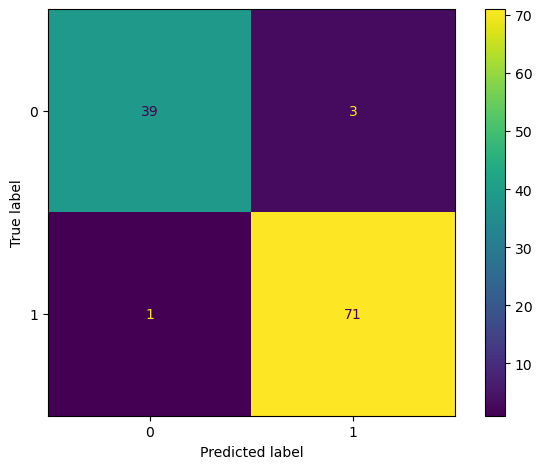

Saved model to lightgbm.joblib


In [11]:
#LightBGM
%pip install lightgbm
!pip install scikit-learn pandas matplotlib joblib
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
 ConfusionMatrixDisplay, precision_score, recall_score, f1_score)
from sklearn.base import clone

data = load_breast_cancer(as_frame=True)
df = data.frame.drop_duplicates().dropna()
X = df.drop(columns="target")
y = df["target"]

print(df.head())
print("Missing values:", int(df.isna().sum().sum()))
print("Class counts:\\n", y.value_counts())

X_train, X_test, y_train, y_test = train_test_split(
 X, y, test_size=0.20, random_state=42, stratify=y
)
from lightgbm import LGBMClassifier 
model = LGBMClassifier(random_state=42, verbosity=-1)
steps = [("model", model)]
pipe = Pipeline(steps)

search = GridSearchCV(pipe, {"model__n_estimators": [50, 100], "model__num_leaves": [15, 31]}, cv=3, scoring="f1_weighted", n_jobs=-1)
search.fit(X_train, y_train)
best_model = search.best_estimator_
print("Best parameters:", search.best_params_)

pred = best_model.predict(X_test)
print(classification_report(y_test, pred, zero_division=0))
print("Accuracy:", accuracy_score(y_test, pred))
print("Precision:", precision_score(y_test, pred, average="weighted", zero_division=0))
print("Recall:", recall_score(y_test, pred, average="weighted", zero_division=0))
print("F1:", f1_score(y_test, pred, average="weighted", zero_division=0))
print("Confusion matrix:\\n", confusion_matrix(y_test, pred))
ConfusionMatrixDisplay.from_predictions(y_test, pred)
plt.tight_layout()
plt.show()

joblib.dump(best_model, "lightgbm.joblib")
print("Saved model to lightgbm.joblib")


   ---------------------------------------- 0.0/100.2 MB ? eta -:--:--
   ---------------------------------------- 1.0/100.2 MB 10.1 MB/s eta 0:00:10
   - -------------------------------------- 2.6/100.2 MB 6.0 MB/s eta 0:00:17
   - -------------------------------------- 4.2/100.2 MB 7.4 MB/s eta 0:00:13
   -- ------------------------------------- 6.0/100.2 MB 7.0 MB/s eta 0:00:14
   -- ------------------------------------- 7.3/100.2 MB 7.2 MB/s eta 0:00:13
   --- ------------------------------------ 8.4/100.2 MB 6.6 MB/s eta 0:00:14
   --- ------------------------------------ 8.9/100.2 MB 6.0 MB/s eta 0:00:16
   ---- ----------------------------------- 10.5/100.2 MB 6.4 MB/s eta 0:00:15
   ---- ----------------------------------- 11.0/100.2 MB 5.7 MB/s eta 0:00:16
   ----- ---------------------------------- 12.6/100.2 MB 5.8 MB/s eta 0:00:16
   ----- ---------------------------------- 13.6/100.2 MB 6.0 MB/s eta 0:00:15
   ------ --------------------------------- 15.5/100.2 MB 6.0 MB/

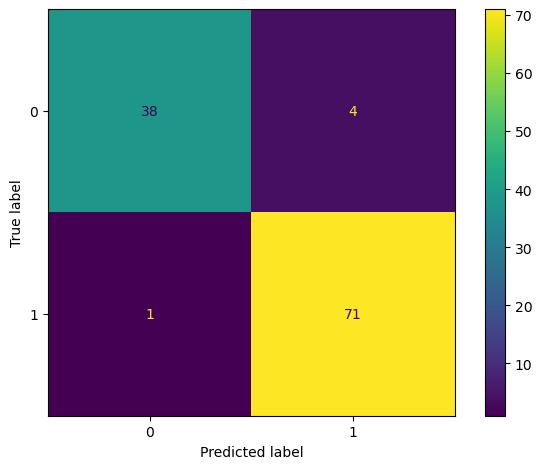

Saved model to catboost.joblib


In [12]:
#CATboost
%pip install catboost
!pip install scikit-learn pandas matplotlib joblib
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
 ConfusionMatrixDisplay, precision_score, recall_score, f1_score)
from sklearn.base import clone

data = load_breast_cancer(as_frame=True)
df = data.frame.drop_duplicates().dropna()
X = df.drop(columns="target")
y = df["target"]

print(df.head())
print("Missing values:", int(df.isna().sum().sum()))
print("Class counts:\\n", y.value_counts())

X_train, X_test, y_train, y_test = train_test_split(
 X, y, test_size=0.20, random_state=42, stratify=y
)
from catboost import CatBoostClassifier
model = CatBoostClassifier(verbose=0, random_seed=42)
steps = [("model", model)]
pipe = Pipeline(steps)

search = GridSearchCV(pipe, {"model__iterations": [50, 100], "model__depth": [4, 6]}, cv=3, scoring="f1_weighted", n_jobs=-1)
search.fit(X_train, y_train)
best_model = search.best_estimator_
print("Best parameters:", search.best_params_)

pred = best_model.predict(X_test)
print(classification_report(y_test, pred, zero_division=0))
print("Accuracy:", accuracy_score(y_test, pred))
print("Precision:", precision_score(y_test, pred, average="weighted", zero_division=0))
print("Recall:", recall_score(y_test, pred, average="weighted", zero_division=0))
print("F1:", f1_score(y_test, pred, average="weighted", zero_division=0))
print("Confusion matrix:\\n", confusion_matrix(y_test, pred))
ConfusionMatrixDisplay.from_predictions(y_test, pred)
plt.tight_layout()
plt.show()

joblib.dump(best_model, "catboost.joblib")
print("Saved model to catboost.joblib")